In [1]:
from padre_meddea.io.file_tools import read_file
from pathlib import Path
import numpy as np
import astropy.units as u
import matplotlib.pyplot as plt
from padre_meddea.util import util as util
from astropy.time import Time

from specutils import SpectralRegion
from specutils.manipulation import extract_region
from astropy.visualization import quantity_support
from astropy.modeling import models
from specutils.fitting import fit_lines

quantity_support()
import specutils
import matplotlib.pyplot as plt
specutils.conf.do_continuum_function_check = False
%load_ext autoreload
%autoreload 2

import padre_meddea
import padre_meddea.spectrum.calibration as cal

from padre_meddea.util.pixels import PixelList

c:\Users\sdchris1\AppData\Local\miniforge3\envs\padre_meddea\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [2]:
padre_meddea.__version__

'0.1.dev88+g3db558a'

In [3]:
str(Time.now())

'2025-11-14 15:47:24.793879'

In [4]:
data_dir = Path('C:/Users/sdchris1/OneDrive - NASA/Desktop/data')

This notebook demonstrates the fast energy calibration tools that are provided in padre_meddea for event list (or photon data). This calibration is specific to a Ba-133 spectrum which is the calibration source on board Meddea.  The main calibration function is cal.The calibration steps are
* determine a rough calibration function by finding the two strongest lines (cal.get_calfunc_barium_rough)
* estimate the location of the rest of the barium lines and fit the precise location of peaks of those lines (cal.fit_peaks)
* determine the linear transformation between adc channel and energy

The primary function which performs all of these steps is cal.calibrate_phlist_barium_linear.
This function returns an array of linear parameters for all pixels.
This array can then be passed into the PhotonList object to create add a new column to the event_list data for the energy of the event.

In [5]:
ba_ph_file = data_dir / Path("padre_meddea_l0test_photon_20250130T104655_v0.1.0.fits")
ba_spec_file = data_dir / Path("padre_meddea_l0test_spectrum_20250130T104648_v0.1.0.fits")
am_ph_file = data_dir / Path("padre_meddea_l0test_photon_20250130T121755_v0.1.0.fits")
am_spec_file = data_dir / Path("padre_meddea_l0test_spectrum_20250130T121750_v0.1.0.fits")
ba_hk_file = data_dir / Path("padre_meddea_l0test_housekeeping_20250130T104656_v0.1.0.fits")
am_hk_file = data_dir / Path("padre_meddea_l0test_housekeeping_20250130T121800_v0.1.0.fits")

# Barium-133 Photon Data

In [6]:
ph_list = read_file(ba_ph_file)

In [7]:
ph_list

PhotonList (7,048,844 events)
2025-01-30 10:46:55.257 - 11:59:56.462 (1hr 13min 1.205s)
{'event_list': <TimeSeries length=7048844>
          time          seqcount clocks  asic ...  pkttimes pktclock pixel
          Time           uint16  uint16 uint8 ...   uint32   uint32  int64
----------------------- -------- ------ ----- ... --------- -------- -----
2025-01-30 10:46:55.257      812      0     0 ... 791549220  5144806     0
2025-01-30 10:46:55.258      812     59     2 ... 791549220  5144806     0
2025-01-30 10:46:55.259      812    138     1 ... 791549220  5144806     4
2025-01-30 10:46:55.259      812    176     0 ... 791549220  5144806     4
2025-01-30 10:46:55.260      812    207     0 ... 791549220  5144806     6
2025-01-30 10:46:55.260      812    211     3 ... 791549220  5144806     6
2025-01-30 10:46:55.261      812    316     3 ... 791549220  5144806     0
2025-01-30 10:46:55.262      812    336     3 ... 791549220  5144806     0
2025-01-30 10:46:55.262      812    407     

In [8]:
ph_list.pkt_list

time,seqcount,pkttimes,pktclock,livetime,inttime,flags,decim_lvl,drop_cnt,int_time_flag,num_hits,rate,corr_rate
Time,uint16,uint32,uint32,uint16,uint16,uint16,uint16,uint16,uint16,uint32,float64,float64
2025-01-30 10:46:55.257,812,791549220,5144806,6519,7210,45200,3,144,32768,143,1549.4972260748962,1713.740604387176
2025-01-30 10:46:55.350,813,791549220,6990913,6032,6721,45198,3,142,32768,143,1662.2340425531913,1852.1012931034481
2025-01-30 10:46:55.436,814,791549220,8729302,6818,7504,45200,3,144,32768,143,1488.789312366738,1638.5853622763275
2025-01-30 10:46:55.532,815,791549220,10634156,6309,6992,45199,3,143,32768,143,1597.808209382151,1770.7838009193217
2025-01-30 10:46:55.621,816,791549220,12427437,5631,6311,45198,3,142,32768,143,1770.2226271589288,1983.9948499378443
2025-01-30 10:46:55.703,817,791549220,14063183,6729,7426,45200,3,144,32768,144,1514.9474818206304,1671.8680338831923
2025-01-30 10:46:55.797,818,791549220,15935995,5552,6254,45200,3,144,32768,143,1786.3567316917172,2012.225324207493
2025-01-30 10:46:55.877,819,791549220,17544407,6363,7053,45199,3,143,32768,143,1583.9890826598612,1755.7559327361307
2025-01-30 10:46:55.967,820,791549220,19347443,6634,7329,45198,3,142,32768,143,1524.338245326784,1684.0330117576125


In [9]:
ph_list.event_list

time,seqcount,clocks,asic,channel,atod,baseline,pkttimes,pktclock,pixel
Time,uint16,uint16,uint8,uint8,uint16,uint16,uint32,uint32,int64
2025-01-30 10:46:55.257,812,0,0,26,1115,3555,791549220,5144806,0
2025-01-30 10:46:55.258,812,59,2,26,1305,3581,791549220,5144806,0
2025-01-30 10:46:55.259,812,138,1,29,1179,3541,791549220,5144806,4
2025-01-30 10:46:55.259,812,176,0,29,1145,3556,791549220,5144806,4
2025-01-30 10:46:55.260,812,207,0,5,1817,3534,791549220,5144806,6
2025-01-30 10:46:55.260,812,211,3,5,472,3472,791549220,5144806,6
2025-01-30 10:46:55.261,812,316,3,26,1247,3553,791549220,5144806,0
2025-01-30 10:46:55.262,812,336,3,26,1143,3498,791549220,5144806,0
2025-01-30 10:46:55.262,812,407,2,0,1131,3578,791549220,5144806,7


In [10]:
hk_ts, cmd_ts = read_file(ba_hk_file)

In [11]:
hk_ts

time,timestamp,fp_temp,dib_temp,hvps_temp,hvps_vsense,hvps_csense,csense_15v,csense_33vd,csense_33va,hit_rate,good_cmd_cnt,error_cnt,heater_pwm_duty_cycle,decimation_rate,error_summary,seqcount
Time,uint32,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16,uint16
2025-01-30 10:46:56.000,791549221,35488,28704,17963,29735,7287,28328,35073,36209,3181,979,0,2151,65325,111,1651
2025-01-30 10:47:01.000,791549226,35488,28704,17956,29732,6885,28314,35072,36229,3258,979,0,2151,65325,111,1652
2025-01-30 10:47:06.000,791549231,35488,28701,17942,29731,7001,28310,34906,36201,3103,979,0,2151,65325,111,1653
2025-01-30 10:47:11.000,791549236,35488,28699,17939,29732,7169,28159,35012,36233,3134,979,0,2151,65325,111,1654
2025-01-30 10:47:16.000,791549241,35488,28694,17934,29735,6867,28316,34902,36228,3307,979,0,2151,65325,111,1655
2025-01-30 10:47:21.000,791549246,35488,28693,17931,29733,6836,28309,34998,36232,3271,979,0,2151,65325,111,1656
2025-01-30 10:47:26.000,791549251,35488,28689,17918,29737,6945,28313,35086,36223,3166,979,0,2151,65325,111,1657
2025-01-30 10:47:31.000,791549256,35488,28688,17911,29735,6739,28308,34897,36233,3176,979,0,2151,65325,111,1658
2025-01-30 10:47:36.000,791549261,35488,28688,17909,29734,6727,28307,34993,36211,3198,979,0,2151,65325,111,1659


In [12]:
cmd_ts

time,pkttimes,pktclock,address,value,seqcount,name
Time,uint32,uint32,uint16,uint16,uint16,bytes17
2025-01-30 10:46:55.418,791549220,8357103,0,17,363,mode
2025-01-30 10:46:55.419,791549220,8389995,1280,22993,364,commit_hash_least
2025-01-30 10:46:55.421,791549220,8424615,1282,2011,365,commit_hash_most
2025-01-30 10:46:55.423,791549220,8459235,1284,36929,366,user_hash_least
2025-01-30 10:46:55.425,791549220,8493855,1286,8984,367,user_hash_most
2025-01-30 10:46:55.426,791549220,8528475,1288,40989,368,build_time_least
2025-01-30 10:46:55.428,791549220,8563095,1290,26522,369,build_time_most


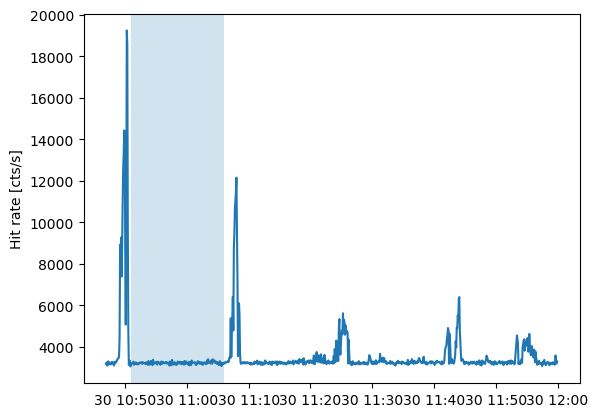

In [13]:
plt.plot(hk_ts.time.to_datetime(), hk_ts['hit_rate'])
plt.ylabel("Hit rate [cts/s]")
good_tr = [Time('2025-01-30T10:51'), Time('2025-01-30T11:06')]
plt.axvspan(good_tr[0].to_datetime(), good_tr[1].to_datetime(), alpha=0.2)


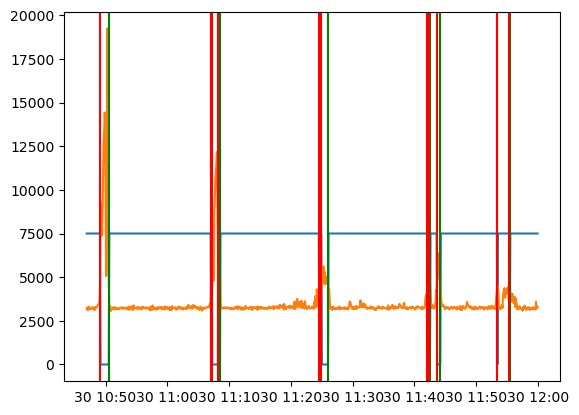

In [14]:
good_times = hk_ts['hit_rate'] < (hk_ts['hit_rate'].min() * 1.45)
start_ind = ~good_times & np.roll(good_times, -1)
end_ind = good_times & np.roll(~good_times, -1)
hk_ts.time[end_ind]
start_times = hk_ts.time[start_ind]
end_times = hk_ts.time[end_ind]

plt.plot(hk_ts.time.to_datetime(), good_times * 7500)
plt.plot(hk_ts.time.to_datetime(), hk_ts['hit_rate'])
for this_s in start_times:
    plt.axvline(this_s.to_datetime(), color='green')
for this_s in end_times:
    plt.axvline(this_s.to_datetime(), color='red')

In [15]:
good_tr = hk_ts.time[start_ind]
good_tr

<Time object: scale='utc' format='iso' value=['2025-01-30 10:50:31.000' '2025-01-30 11:07:06.000'
 '2025-01-30 11:08:11.000' '2025-01-30 11:08:31.000'
 '2025-01-30 11:24:41.000' '2025-01-30 11:26:01.000'
 '2025-01-30 11:42:21.000' '2025-01-30 11:42:31.000'
 '2025-01-30 11:44:11.000' '2025-01-30 11:53:26.000'
 '2025-01-30 11:55:26.000']>

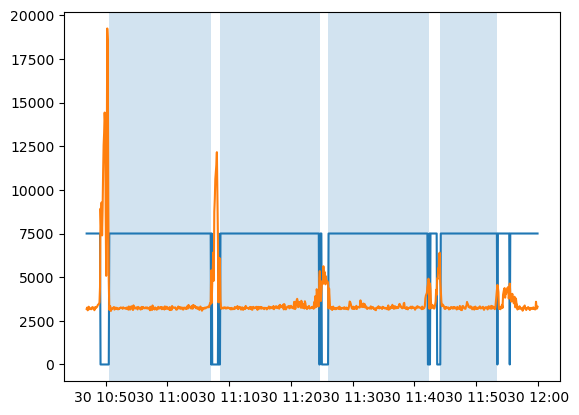

In [16]:
plt.plot(hk_ts.time.to_datetime(), good_times * 7500)
plt.plot(hk_ts.time.to_datetime(), hk_ts['hit_rate'])
plt.axvspan(good_tr[0].to_datetime(), good_tr[1].to_datetime(), alpha=0.2)
plt.axvspan(good_tr[3].to_datetime(), good_tr[4].to_datetime(), alpha=0.2)
plt.axvspan(good_tr[5].to_datetime(), good_tr[6].to_datetime(), alpha=0.2)
plt.axvspan(good_tr[8].to_datetime(), good_tr[9].to_datetime(), alpha=0.2)
good_trs = [[good_tr[0], good_tr[1]], [good_tr[3], good_tr[4]], [good_tr[5], good_tr[6]], [good_tr[8], good_tr[9]]]



In [17]:
good_trs

[[<Time object: scale='utc' format='iso' value=2025-01-30 10:50:31.000>,
  <Time object: scale='utc' format='iso' value=2025-01-30 11:07:06.000>],
 [<Time object: scale='utc' format='iso' value=2025-01-30 11:08:31.000>,
  <Time object: scale='utc' format='iso' value=2025-01-30 11:24:41.000>],
 [<Time object: scale='utc' format='iso' value=2025-01-30 11:26:01.000>,
  <Time object: scale='utc' format='iso' value=2025-01-30 11:42:21.000>],
 [<Time object: scale='utc' format='iso' value=2025-01-30 11:44:11.000>,
  <Time object: scale='utc' format='iso' value=2025-01-30 11:53:26.000>]]

In [18]:
gph_list = ph_list[good_trs[0][0]: good_trs[0][1]]
print(len(gph_list.event_list))
for this_tr in good_trs[1:]:
    print(this_tr)
    print(len(gph_list.event_list))
    print(len(ph_list[this_tr[0]:this_tr[1]].event_list))
    gph_list += ph_list[this_tr[0]:this_tr[1]]

1590321
[<Time object: scale='utc' format='iso' value=2025-01-30 11:08:31.000>, <Time object: scale='utc' format='iso' value=2025-01-30 11:24:41.000>]
1590321
1550743
[<Time object: scale='utc' format='iso' value=2025-01-30 11:26:01.000>, <Time object: scale='utc' format='iso' value=2025-01-30 11:42:21.000>]
3141064
1568338
[<Time object: scale='utc' format='iso' value=2025-01-30 11:44:11.000>, <Time object: scale='utc' format='iso' value=2025-01-30 11:53:26.000>]
4709402
888951


Times with increased hit rate is due to microphonics from the cooling system. The following calibration could be improved by including more data.

In [19]:
ph_list = gph_list

In [20]:
all_pixel_list = PixelList().all()
all_pixel_list

asic,pixel,channel,id,label
uint8,uint8,uint8,uint16,str12
0,0,26,51738,Det0Pixel0L
0,1,15,51727,Det0Pixel1L
0,2,8,51720,Det0Pixel2L
0,3,1,51713,Det0Pixel3L
0,4,29,51741,Det0Pixel4L
0,5,18,51730,Det0Pixel5L
0,6,5,51717,Det0Pixel6L
0,7,0,51712,Det0Pixel7L
0,8,30,51742,Det0Pixel8S


Text(0.5, 1.0, 'All pixels')

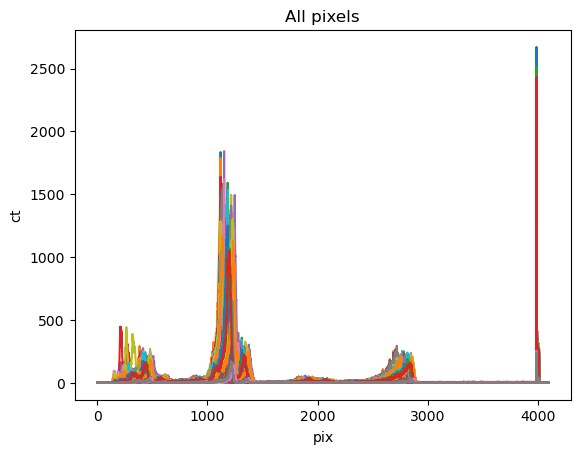

In [21]:
fig, ax = plt.subplots()
for this_pixel in all_pixel_list:
    this_spec = ph_list.spectrum(pixel_list=this_pixel)
    ax.plot(this_spec.spectral_axis, this_spec.flux)
plt.title("All pixels")

Text(0.5, 1.0, "['Det0Pixel0L']")

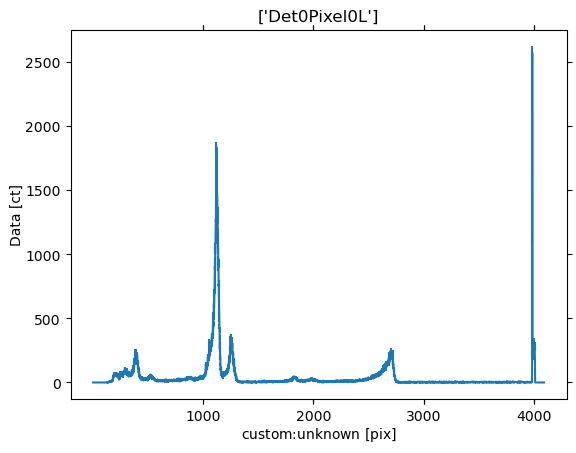

In [22]:
select_pixel = PixelList(asics=[0], pixels=[0])
ph_list.spectrum(pixel_list=select_pixel).plot()
plt.title(f"{select_pixel['label'].value}")

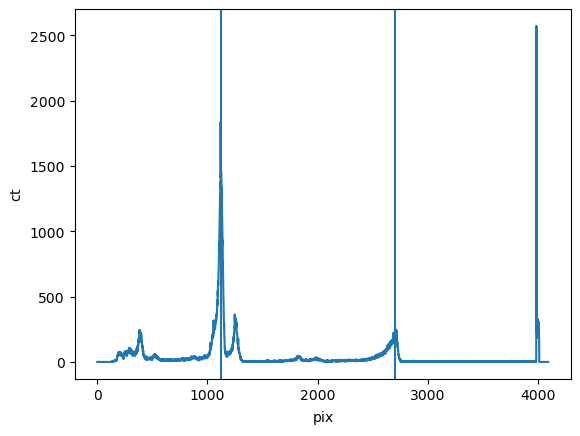

In [23]:
select_pixel = PixelList(asics=[0], pixels=[0])
this_spec = ph_list.spectrum(pixel_list=select_pixel)
f = cal.get_calfunc_barium_rough(this_spec, plot=True)


In [24]:
#lin_cal_params = cal.calibrate_phlist_barium_linear(ph_list, plot=True)  # outputs 2 plots per pixel
lin_cal_params = cal.calibrate_phlist_barium_linear(ph_list)


In [25]:
lin_cal_params.shape

(4, 12, 2)

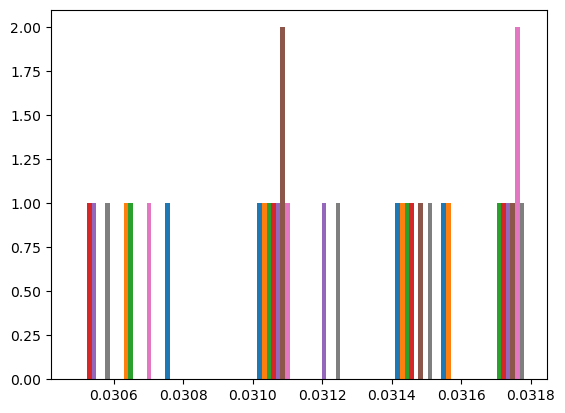

In [26]:
plt.hist(lin_cal_params[:, 0:8, 0]);


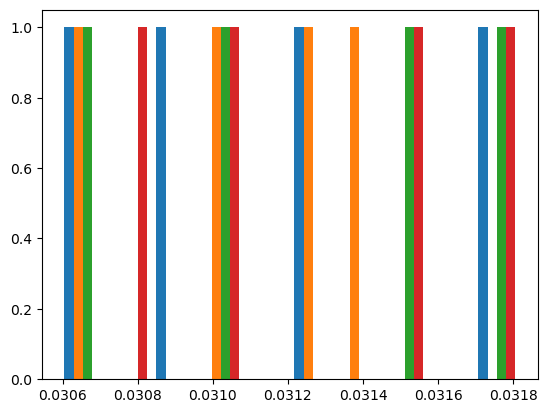

In [27]:
plt.hist(lin_cal_params[:, 8:, 0]);


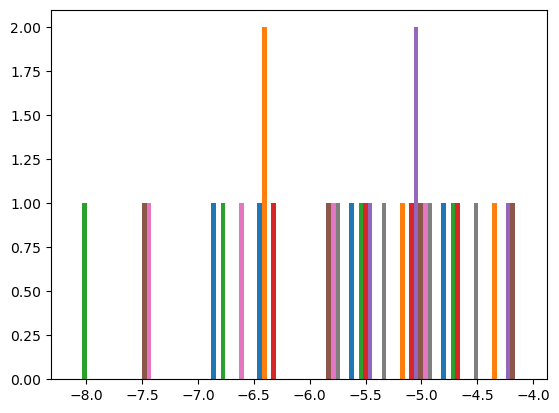

In [28]:
plt.hist(lin_cal_params[:, 0:8, 1]);


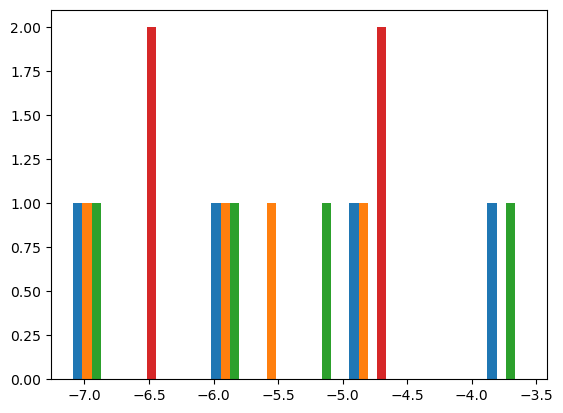

In [29]:
plt.hist(lin_cal_params[:, 8:, 1]);


In [30]:
cal_ph_list = cal.calibrate_linear_phlist(ph_list, lin_cal_params)

<WCSAxes: ylabel='Data [ct]'>

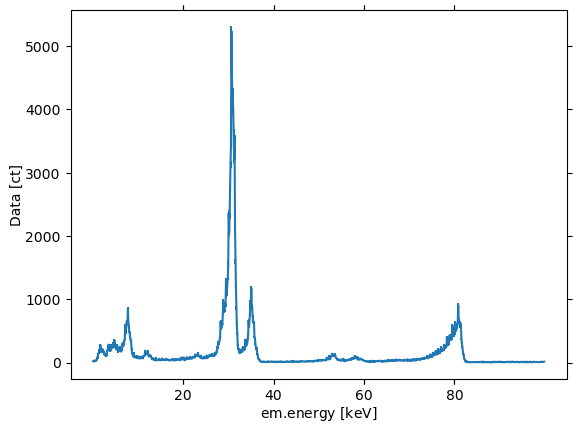

In [31]:
select_pixel = PixelList(asics=[0], pixels=[0])
cal_ph_list.spectrum(pixel_list=select_pixel, calibrate=True).plot()

In [41]:
cal_ph_list.spectrum(pixel_list=select_pixel, calibrate=True).spectral_axis

<SpectralAxis [5.000e-02, 1.500e-01, 2.500e-01, 3.500e-01, 4.500e-01, 5.500e-01,
   6.500e-01, 7.500e-01, 8.500e-01, 9.500e-01, 1.050e+00, 1.150e+00,
   1.250e+00, 1.350e+00, 1.450e+00, 1.550e+00, 1.650e+00, 1.750e+00,
   1.850e+00, 1.950e+00, 2.050e+00, 2.150e+00, 2.250e+00, 2.350e+00,
   2.450e+00, 2.550e+00, 2.650e+00, 2.750e+00, 2.850e+00, 2.950e+00,
   3.050e+00, 3.150e+00, 3.250e+00, 3.350e+00, 3.450e+00, 3.550e+00,
   3.650e+00, 3.750e+00, 3.850e+00, 3.950e+00, 4.050e+00, 4.150e+00,
   4.250e+00, 4.350e+00, 4.450e+00, 4.550e+00, 4.650e+00, 4.750e+00,
   4.850e+00, 4.950e+00, 5.050e+00, 5.150e+00, 5.250e+00, 5.350e+00,
   5.450e+00, 5.550e+00, 5.650e+00, 5.750e+00, 5.850e+00, 5.950e+00,
   6.050e+00, 6.150e+00, 6.250e+00, 6.350e+00, 6.450e+00, 6.550e+00,
   6.650e+00, 6.750e+00, 6.850e+00, 6.950e+00, 7.050e+00, 7.150e+00,
   7.250e+00, 7.350e+00, 7.450e+00, 7.550e+00, 7.650e+00, 7.750e+00,
   7.850e+00, 7.950e+00, 8.050e+00, 8.150e+00, 8.250e+00, 8.350e+00,
   8.450e+00, 8.550e+0

Text(0.5, 1.0, 'All large pixels')

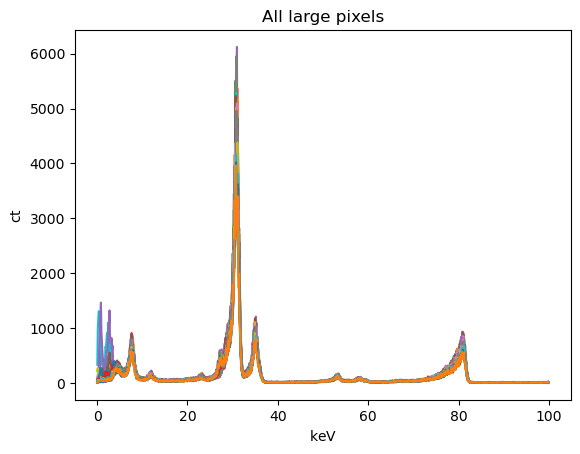

In [32]:
fig, ax = plt.subplots()
for this_pixel in all_pixel_list.select_large():
    this_spec = ph_list.spectrum(pixel_list=this_pixel, calibrate=True)
    ax.plot(this_spec.spectral_axis, this_spec.flux)
plt.title("All large pixels")

Text(0.5, 1.0, 'All small pixels')

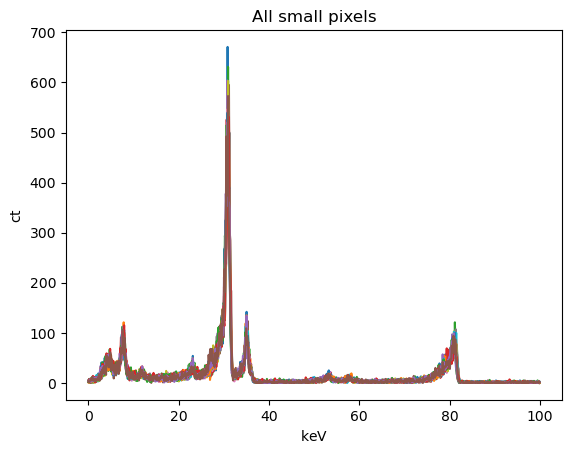

In [33]:
fig, ax = plt.subplots()
for this_pixel in all_pixel_list.select_small():
    this_spec = ph_list.spectrum(pixel_list=this_pixel, calibrate=True)
    ax.plot(this_spec.spectral_axis, this_spec.flux)
plt.title("All small pixels")

In [34]:
ba_line_energies = [7.8, 11.8, 30.85, 35, 53.5, 57.8, 81] * u.keV

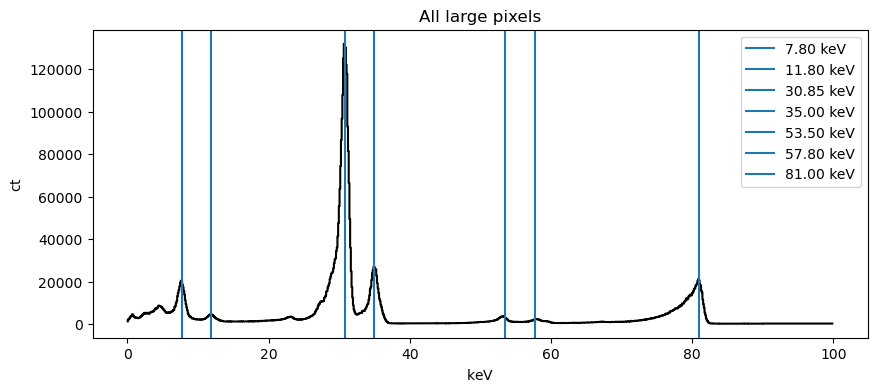

In [35]:
fig, ax = plt.subplots(figsize=(10, 4))
large_pix_spec = ph_list.spectrum(pixel_list=all_pixel_list.select_large(), calibrate=True)
ax.step(large_pix_spec.spectral_axis, large_pix_spec.flux, color='black')
plt.title("All large pixels")
for this_energy in ba_line_energies:
    ax.axvline(this_energy, label=f"{this_energy:0.2f}")
plt.legend()

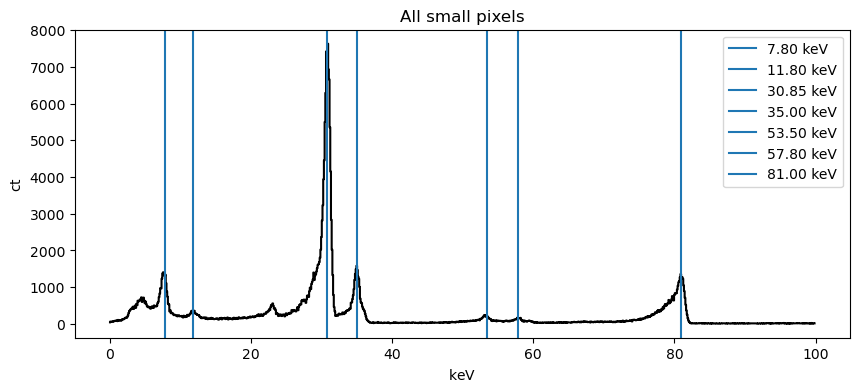

In [36]:
fig, ax = plt.subplots(figsize=(10, 4))
small_pix_spec = ph_list.spectrum(pixel_list=all_pixel_list.select_small(), calibrate=True)
ax.step(small_pix_spec.spectral_axis, small_pix_spec.flux, color='black')
plt.title("All small pixels")
for this_energy in ba_line_energies:
    ax.axvline(this_energy, label=f"{this_energy:0.2f}")
plt.legend()

## Low energy threshold requirement

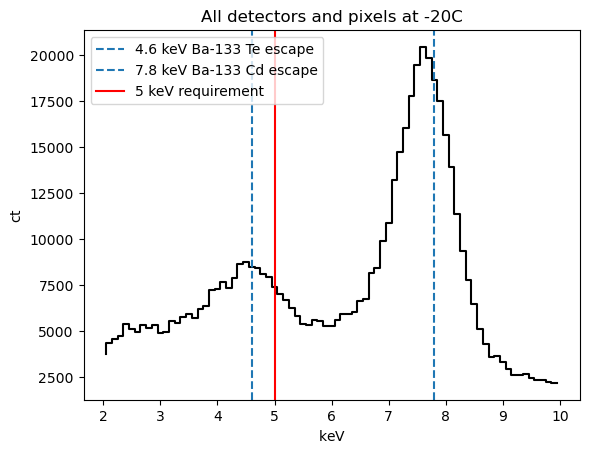

In [37]:
fig, ax = plt.subplots()
sub_spec = extract_region(large_pix_spec, SpectralRegion([[2, 10] * u.keV]))
ax.step(sub_spec.spectral_axis, sub_spec.flux, color="black")
plt.axvline(4.6 * u.keV, label="4.6 keV Ba-133 Te escape", linestyle='dashed')
plt.axvline(7.8 * u.keV, label="7.8 keV Ba-133 Cd escape", linestyle='dashed')
plt.axvline(5, label='5 keV requirement', color='red')
plt.title("All detectors and pixels at -20C")
plt.legend()

## High energy threshold

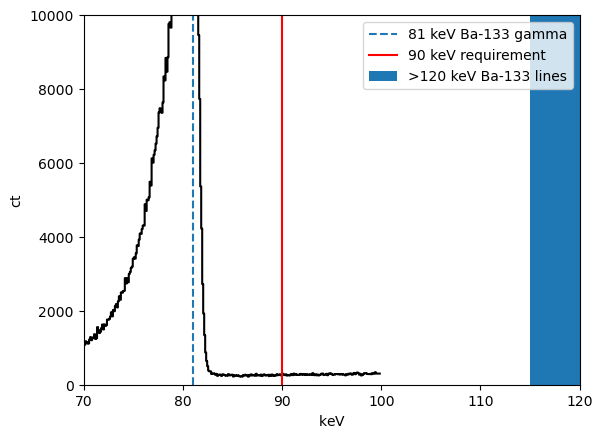

In [38]:
energy_bins = np.arange(0, 120, 0.1)
fig, ax = plt.subplots()
ax.step(large_pix_spec.spectral_axis, large_pix_spec.flux, color="black")
ax.axvline(ba_line_energies[-1], label="81 keV Ba-133 gamma", linestyle='dashed')
ax.axvline(90 * u.keV, label='90 keV requirement', color='red')
ax.axvspan(115 * u.keV, 120 * u.keV, label='>120 keV Ba-133 lines')
plt.xlim(70, 120)
plt.ylim(0, 10000)
plt.legend()

In [39]:
from astropy.modeling import models, fitting
from specutils.analysis import fwhm
from specutils.fitting import estimate_line_parameters

from padre_meddea.spectrum.calibration import crystal_ball
from scipy.optimize import curve_fit
from scipy.stats import crystalball


ERROR: ImportError: cannot import name 'crystal_ball' from 'padre_meddea.spectrum.calibration' (C:\Users\sdchris1\Documents\GitHub\padre_meddea\padre_meddea\spectrum\calibration.py) [IPython.core.interactiveshell]
2025-11-14 10:48:26 - swxsoc - ERROR: ImportError: cannot import name 'crystal_ball' from 'padre_meddea.spectrum.calibration' (C:\Users\sdchris1\Documents\GitHub\padre_meddea\padre_meddea\spectrum\calibration.py)


ImportError: cannot import name 'crystal_ball' from 'padre_meddea.spectrum.calibration' (C:\Users\sdchris1\Documents\GitHub\padre_meddea\padre_meddea\spectrum\calibration.py)

In [ ]:
def parse_sys_errors(sys_errors):
    """Given an error code, returns a dictionary containing each error status as a boolean"""
    errorlist = {   "uart_parity_err":  False,
                    "ping1_parity_err": False,
                    "ping2_parity_err": False,
                    "hist_parity_err":  False,
                    "heater_err":       False,
                    "caliste_reg_err":  False,
                    "caliste_seu":      False,
                    "rogue_pps":        False,
                    "fake_evt_flg":     False,
                    "freewheel_pps":    False}

    if (sys_errors & 0x0001):
        errorlist["uart_parity_err"] = True;
    if (sys_errors & 0x0002):
        errorlist["ping1_parity_err"] = True;
    if (sys_errors & 0x0004):
        errorlist["ping2_parity_err"] = True;
    if (sys_errors & 0x0008):
        errorlist["hist_parity_err"] = True;
    if (sys_errors & 0x0010):
        errorlist["heater_err"] = True;
    if (sys_errors & 0x0020):
        errorlist["caliste_reg_err"] = True;
    if (sys_errors & 0x0040):
        errorlist["caliste_seu"] = True;
    if (sys_errors & 0x0080):
        errorlist["rogue_pps"] = True;
    if (sys_errors & 0x0100):
        errorlist["fake_evt_flg"] = True;
    if (sys_errors & 0x0200):
        errorlist["freewheel_pps"] = True;
    if (sys_errors & 0xFC00):
        #TODO: These bits are un-used and should be zero. Not sure how we want to deal with the case where they aren't. Should it raise expection? Print a message? Do nothing?
        pass
        
    
    return errorlist

parse_sys_errors(0xfd7f)

{'uart_parity_err': True,
 'ping1_parity_err': True,
 'ping2_parity_err': True,
 'hist_parity_err': True,
 'heater_err': True,
 'caliste_reg_err': True,
 'caliste_seu': True,
 'rogue_pps': False,
 'fake_evt_flg': True,
 'freewheel_pps': False}

In [ ]:
def plot_fwhm(spec, line_energy):
    line_region = SpectralRegion(line_energy - 1 * u.keV, line_energy + 1 * u.keV)
    sub_spec = extract_region(spec, line_region)
    result = estimate_line_parameters(sub_spec, models.Gaussian1D())
    g_init = models.Gaussian1D(
        amplitude=result.amplitude, mean=result.mean, stddev=result.stddev
    )
    g_fit = fit_lines(sub_spec, g_init)
    x = sub_spec.spectral_axis
    y = sub_spec.flux

    plt.step(x, y, color="black")
    plt.plot(x, g_fit(x), label=f"gauss fwhm {g_fit.fwhm:0.2f}")
    # fit = fitting.LMLSQFitter()
    # bigauss = BiGaussian1D(amplitude=result.amplitude.value, mean=result.mean.value, stddev1=result.stddev.value, stddev2=result.stddev.value * 0.5)
    # fitted_line = fit(bigauss, x.value, sub_spec.flux.value, maxiter=2000)
    # plt.plot(x, fitted_line(x.value))
    spec_fwhm = fwhm(sub_spec)
    max_ind = np.argmax(sub_spec.flux)
    left = x[max_ind] - spec_fwhm / 2.0
    right = x[max_ind] + spec_fwhm / 2.0

    #fit = fitting.TRFLSQFitter()
    #popt, pcov = curve_fit(crystal_ball, x.value, y.value, p0=[0.5, 1.5, line_energy.value, 1.5, y.value.sum()])

    plt.axvline(x[max_ind])
    plt.axvspan(left, right, alpha=0.2, label=f"{spec_fwhm:0.2f}")

    plt.step(x, y, color='black')
    #plt.plot(x, crystal_ball(x.value, *popt), label=f'fit {popt[2]:0.2f} FWHM {2.355 * popt[3]:0.2f} keV')
    plt.legend()

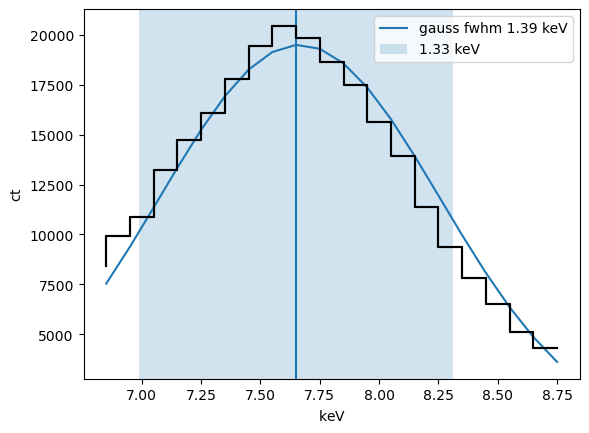

In [ ]:
plot_fwhm(large_pix_spec, ba_line_energies[0])

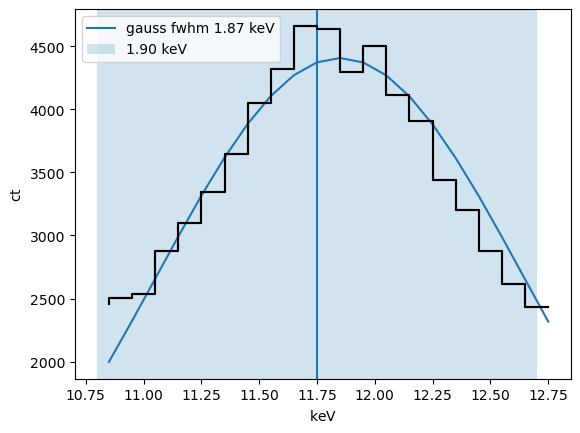

In [ ]:
plot_fwhm(large_pix_spec, ba_line_energies[1])

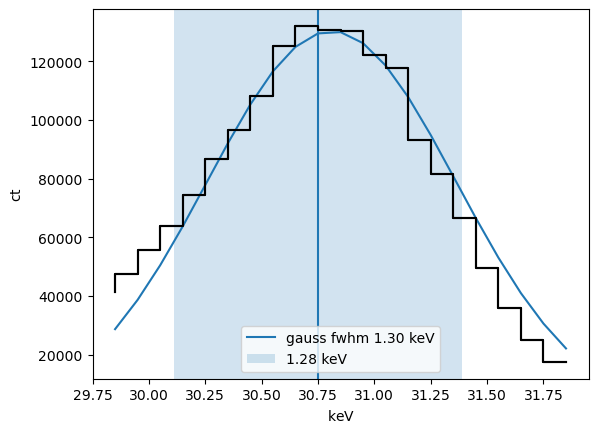

In [ ]:
plot_fwhm(large_pix_spec, ba_line_energies[2])

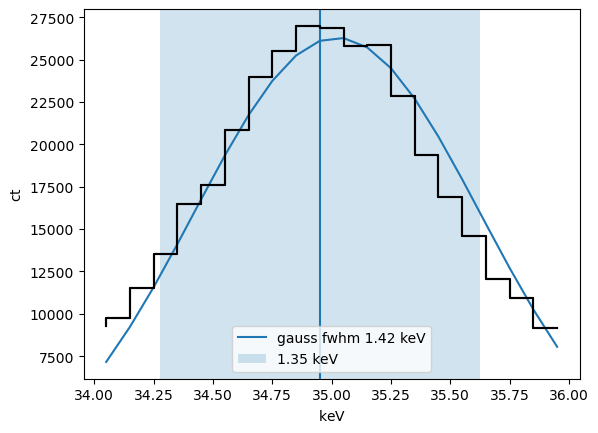

In [ ]:
plot_fwhm(large_pix_spec, ba_line_energies[3])


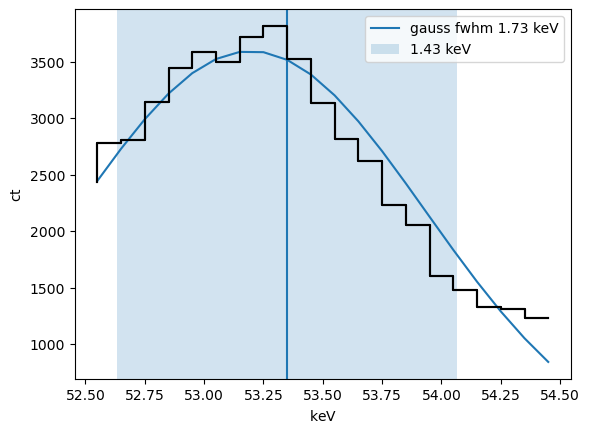

In [ ]:
plot_fwhm(large_pix_spec, ba_line_energies[4])


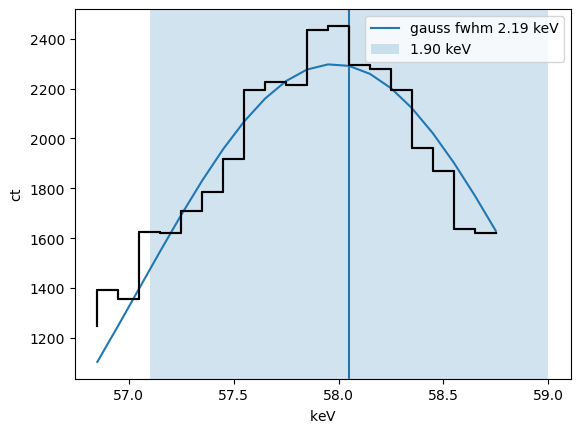

In [ ]:
plot_fwhm(large_pix_spec, ba_line_energies[5])


[2.08227502e-01 3.54483783e+00 8.09773200e+01 5.43532850e-01
 8.95474008e+04]
[2.08227502e-01 3.54483783e+00 8.09773200e+01 5.43532850e-01
 8.95474008e+04]


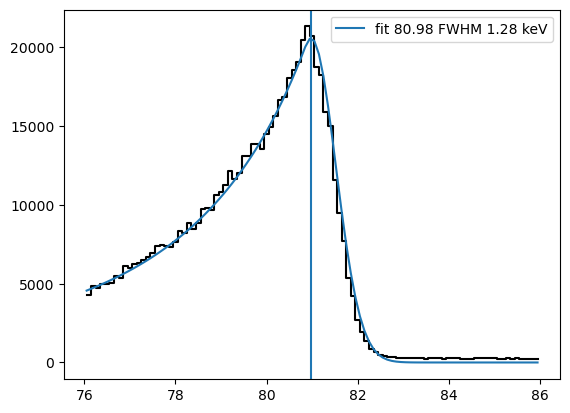

In [ ]:
line_energy = ba_line_energies[6]
line_region = SpectralRegion(line_energy - 5 * u.keV, line_energy + 5 * u.keV)
sub_spec = extract_region(large_pix_spec, line_region)
x = sub_spec.spectral_axis.value
y = sub_spec.flux.value

fit = fitting.TRFLSQFitter()
popt, pcov = curve_fit(crystal_ball, x, y, p0=[0.5, 1.5, 81., 1.5, sub_spec.flux.value.sum()])
plt.step(x, y, color='black')
plt.plot(x, crystal_ball(x, *popt), label=f'fit {popt[2]:0.2f} FWHM {2.355 * popt[3]:0.2f} keV')
plt.axvline(popt[2])
plt.legend()
print(popt)

[1.50000e+00 5.00000e-01 8.10000e+01 6.54398e+05]


C:\Users\sdchris1\AppData\Local\Temp\1\ipykernel_28532\2902121041.py:8: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(crystalball.pdf, x, y, p0=[1.5, 0.5, 81., sub_spec.flux.value.sum()])


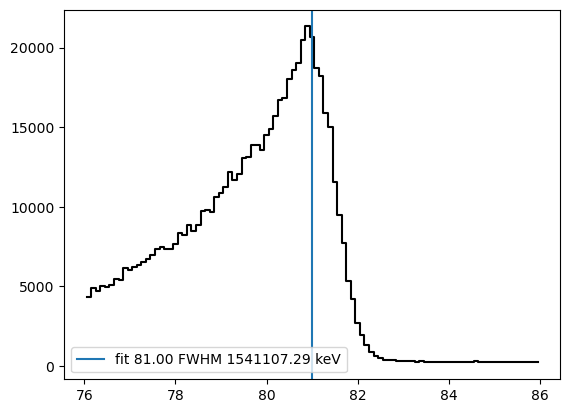

In [ ]:
line_energy = ba_line_energies[6]
line_region = SpectralRegion(line_energy - 5 * u.keV, line_energy + 5 * u.keV)
sub_spec = extract_region(large_pix_spec, line_region)
x = sub_spec.spectral_axis.value
y = sub_spec.flux.value

fit = fitting.TRFLSQFitter()
popt, pcov = curve_fit(crystalball.pdf, x, y, p0=[1.5, 0.5, 81., sub_spec.flux.value.sum()])
print(popt)
plt.step(x, y, color='black')
plt.plot(x, crystalball.pdf(x, *popt), label=f'fit {popt[2]:0.2f} FWHM {2.355 * popt[3]:0.2f} keV')
plt.axvline(popt[2])
plt.legend()

Does not work well due to significant tailing at this energy.

## Americium data

In [ ]:
am_lines = [13.9, 17.8, 20.8, 26.4, 59.5] * u.keV

In [ ]:
am_ph_list = read_file(am_ph_file)

In [ ]:
cal_am_ph_list = cal.calibrate_linear_phlist(am_ph_list, lin_cal_params)

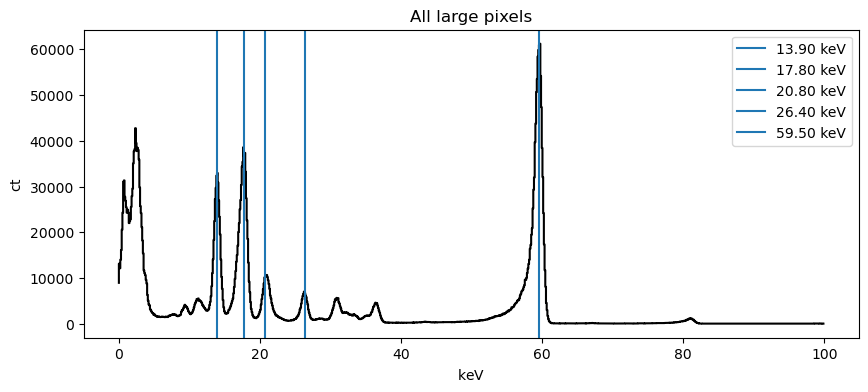

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
large_pix_am_spec = cal_am_ph_list.spectrum(pixel_list=all_pixel_list.select_large(), calibrate=True)
ax.step(large_pix_am_spec.spectral_axis, large_pix_am_spec.flux, color='black')
plt.title("All large pixels")
for this_energy in am_lines:
    ax.axvline(this_energy, label=f"{this_energy:0.2f}")
plt.legend()


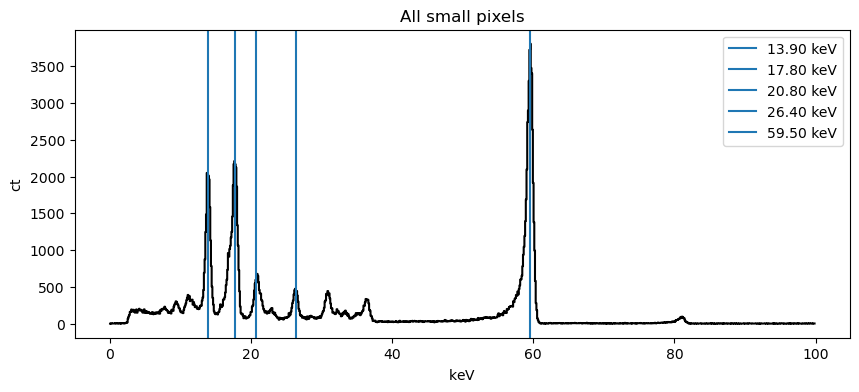

In [ ]:
fig, ax = plt.subplots(figsize=(10, 4))
small_pix_am_spec = cal_am_ph_list.spectrum(pixel_list=all_pixel_list.select_small(), calibrate=True)
ax.step(small_pix_am_spec.spectral_axis, small_pix_am_spec.flux, color='black')
plt.title("All small pixels")
for this_energy in am_lines:
    ax.axvline(this_energy, label=f"{this_energy:0.2f}")
plt.legend()

